# Feature Selection & Đánh giá mô hình — House Price Prediction

## 1. Imports & Tải dữ liệu

In [1]:
from functools import partial
from pathlib import Path
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import (
    RFE,
    SelectFromModel,
    SelectKBest,
    f_regression,
    mutual_info_regression,
)
from sklearn.linear_model import LassoCV, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')


ROOT = Path.cwd()
if not (ROOT / 'train_processed.csv').exists():
    ROOT = ROOT.parent

data = pd.read_csv(ROOT / 'train_processed.csv')


train_df = data[data['split'] == 'train'].reset_index(drop=True)
test_df  = data[data['split'] == 'test'].reset_index(drop=True)

X_train = train_df.drop(columns=['log_SalePrice', 'split'])
y_train = train_df['log_SalePrice']
X_test  = test_df.drop(columns=['log_SalePrice', 'split'])
y_test  = test_df['log_SalePrice']

RANDOM_STATE = 42
N_SPLITS     = 5
K            = 50        

cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape} | Test: {X_test.shape} | K = {K}')

Train: (1166, 265) | Test: (292, 265) | K = 50


## 2. Định nghĩa mô hình & Selector

In [2]:

def make_models():
    return {
        'SVR': SVR(C=10.0, epsilon=0.01, kernel='rbf'),
        'RandomForest': RandomForestRegressor(
            n_estimators=400, max_features=0.8,
            random_state=RANDOM_STATE, n_jobs=-1,
        ),
        'XGBoost': XGBRegressor(
            n_estimators=400, max_depth=4, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8,
            objective='reg:squarederror', eval_metric='rmse',
            random_state=RANDOM_STATE, n_jobs=1,
        ),
    }

def _rfe_estimator(model_name):

    if model_name == 'SVR':
        return Ridge(alpha=10.0)
    if model_name == 'RandomForest':
        return RandomForestRegressor(
            n_estimators=50, max_features=0.3,
            random_state=RANDOM_STATE, n_jobs=-1,
        )
    return XGBRegressor(
        n_estimators=100, max_depth=4, learning_rate=0.1,
        random_state=RANDOM_STATE, n_jobs=1,
    )

def make_selector(technique, model_name):

    if technique == 'baseline':
        return 'passthrough'
    if technique == 'filter_kbest':
        return SelectKBest(score_func=f_regression, k=K)
    if technique == 'filter_mi':
        return SelectKBest(
            score_func=partial(mutual_info_regression, random_state=RANDOM_STATE),
            k=K,
        )
    if technique == 'wrapper_rfe':
        return RFE(_rfe_estimator(model_name), n_features_to_select=K, step=20)
    if technique == 'embedded_lasso':
    
        return SelectFromModel(
            LassoCV(cv=5, random_state=RANDOM_STATE, max_iter=50_000),
            threshold=1e-5,
        )
    if technique == 'embedded_rf':
        return SelectFromModel(
            RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
            max_features=K,
            threshold=-float('inf'),
        )
    raise ValueError(f'Kỹ thuật không hợp lệ: {technique}')

def make_pipeline(technique, model_name, estimator):
  
    return Pipeline([
        ('selector', make_selector(technique, model_name)),
        ('model',    estimator),
    ])

TECHNIQUES = [
    'baseline',        
    'filter_kbest',    
    'filter_mi',       
    'wrapper_rfe',     
    'embedded_lasso',  
    'embedded_rf',     
]

print(f'Số kỹ thuật: {len(TECHNIQUES)} | Số mô hình: {len(make_models())}')
print(f'Tổng số thí nghiệm: {len(TECHNIQUES) * len(make_models())}')

Số kỹ thuật: 6 | Số mô hình: 3
Tổng số thí nghiệm: 18


## 3. Hàm đánh giá Cross-Validation + Test Set

In [3]:
def _compute_metrics(actual_log, preds_log):
    """Tính RMSE, MAE, R² trên thang log và thang giá gốc."""
    actual_orig = np.expm1(actual_log)
    preds_orig  = np.maximum(np.expm1(preds_log), 0)
    return {
        'log_rmse':  mean_squared_error(actual_log,  preds_log)  ** 0.5,
        'log_mae':   mean_absolute_error(actual_log,  preds_log),
        'log_r2':    r2_score(actual_log,  preds_log),
        'orig_rmse': mean_squared_error(actual_orig, preds_orig) ** 0.5,
        'orig_mae':  mean_absolute_error(actual_orig, preds_orig),
        'orig_r2':   r2_score(actual_orig, preds_orig),
    }

def count_selected_features(fitted_pipeline):
    
    selector = fitted_pipeline.named_steps['selector']
    if selector == 'passthrough':
        return X_train.shape[1]
    return int(selector.get_support().sum())

def evaluate_model(technique, name, estimator):
    
    fold_metrics = []
    fold_times   = []

    for tr_idx, val_idx in cv.split(X_train):
        fold_model = clone(estimator)
        t0 = time.perf_counter()
        fold_model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        preds_log = fold_model.predict(X_train.iloc[val_idx])
        fold_times.append(time.perf_counter() - t0)
        fold_metrics.append(_compute_metrics(y_train.iloc[val_idx].to_numpy(), preds_log))

    folds_df = pd.DataFrame(fold_metrics)

    final_model = clone(estimator)
    final_model.fit(X_train, y_train)
    test_preds  = final_model.predict(X_test)
    test_metrics = _compute_metrics(y_test.to_numpy(), test_preds)
    n_feat = count_selected_features(final_model)

    row = {'technique': technique, 'model': name, 'n_features': n_feat}

    for col in folds_df.columns:
        row[f'cv_{col}']     = folds_df[col].mean()
        row[f'cv_{col}_std'] = folds_df[col].std(ddof=1)
    for k, v in test_metrics.items():
        row[f'test_{k}'] = v
    row['cv_seconds'] = sum(fold_times)
    return row

## 4. Chạy thí nghiệm

In [4]:
rows = []

for technique in TECHNIQUES:
    label = 'BASELINE (tất cả feature)' if technique == 'baseline' else technique.upper()
    print(f'\n=== {label} ===')
    for name, estimator in make_models().items():
        pipe = make_pipeline(technique, name, estimator)
        row  = evaluate_model(technique, name, pipe)
        rows.append(row)
        print(
            f'  {name:15s}  '
            f'CV RMSE = {row["cv_log_rmse"]:.4f} ± {row["cv_log_rmse_std"]:.4f}  '
            f'Test RMSE = {row["test_log_rmse"]:.4f}  '
            f'features = {row["n_features"]}'
        )

results = pd.DataFrame(rows).sort_values('cv_log_rmse').reset_index(drop=True)
print('\n✅ Hoàn thành!')


=== BASELINE (tất cả feature) ===
  SVR              CV RMSE = 0.1389 ± 0.0155  Test RMSE = 0.1419  features = 265
  RandomForest     CV RMSE = 0.1330 ± 0.0143  Test RMSE = 0.1404  features = 265
  XGBoost          CV RMSE = 0.1151 ± 0.0128  Test RMSE = 0.1200  features = 265

=== FILTER_KBEST ===
  SVR              CV RMSE = 0.1501 ± 0.0076  Test RMSE = 0.1634  features = 50
  RandomForest     CV RMSE = 0.1379 ± 0.0165  Test RMSE = 0.1499  features = 50
  XGBoost          CV RMSE = 0.1308 ± 0.0156  Test RMSE = 0.1441  features = 50

=== FILTER_MI ===
  SVR              CV RMSE = 0.1478 ± 0.0126  Test RMSE = 0.1474  features = 50
  RandomForest     CV RMSE = 0.1336 ± 0.0147  Test RMSE = 0.1438  features = 50
  XGBoost          CV RMSE = 0.1253 ± 0.0158  Test RMSE = 0.1298  features = 50

=== WRAPPER_RFE ===
  SVR              CV RMSE = 0.1467 ± 0.0042  Test RMSE = 0.1443  features = 50
  RandomForest     CV RMSE = 0.1333 ± 0.0149  Test RMSE = 0.1427  features = 50
  XGBoost          C

## 5. Bảng kết quả tổng hợp

In [5]:
display_cols = [
    'technique', 'model',
    'cv_log_rmse', 'cv_log_rmse_std',
    'cv_log_r2',   'cv_log_r2_std',
    'test_log_rmse', 'test_log_r2',
    'cv_orig_rmse', 'test_orig_rmse',
    'n_features',   'cv_seconds',
]
display(results[display_cols].round(4))

,technique,model,cv_log_rmse,cv_log_rmse_std,cv_log_r2,cv_log_r2_std,test_log_rmse,test_log_r2,cv_orig_rmse,test_orig_rmse,n_features,cv_seconds
0,baseline,XGBoost,0.1151,0.0128,0.9151,0.0087,0.1200,0.9146,22882.1156,19196.4627,265,3.3402
1,embedded_lasso,XGBoost,0.1173,0.0129,0.9119,0.0083,0.1189,0.9162,23366.4183,18985.3730,93,3.2124
2,wrapper_rfe,XGBoost,0.1196,0.0124,0.9082,0.0096,0.1208,0.9134,22747.9370,19036.5504,50,7.3513
3,embedded_rf,XGBoost,0.1228,0.0139,0.9034,0.0109,0.1245,0.9081,24539.5116,19404.7350,50,3.3586
4,filter_mi,XGBoost,0.1253,0.0158,0.8996,0.0117,0.1298,0.9001,24346.6144,20579.2420,50,7.5420
5,filter_kbest,XGBoost,0.1308,0.0156,0.8905,0.0134,0.1441,0.8768,25216.8682,21932.5823,50,1.2654
6,embedded_lasso,RandomForest,0.1318,0.0141,0.8888,0.0097,0.1413,0.8815,26530.1274,22749.5868,93,5.5807
7,baseline,RandomForest,0.1330,0.0143,0.8868,0.0092,0.1404,0.8830,26634.2824,22504.7566,265,5.3028
8,wrapper_rfe,RandomForest,0.1333,0.0149,0.8863,0.0106,0.1427,0.8792,26515.2765,22736.0410,50,10.7602
9,embedded_rf,RandomForest,0.1334,0.0143,0.8861,0.0099,0.1421,0.8802,26456.2869,22427.5089,50,5.4742


## 6. Trực quan hoá

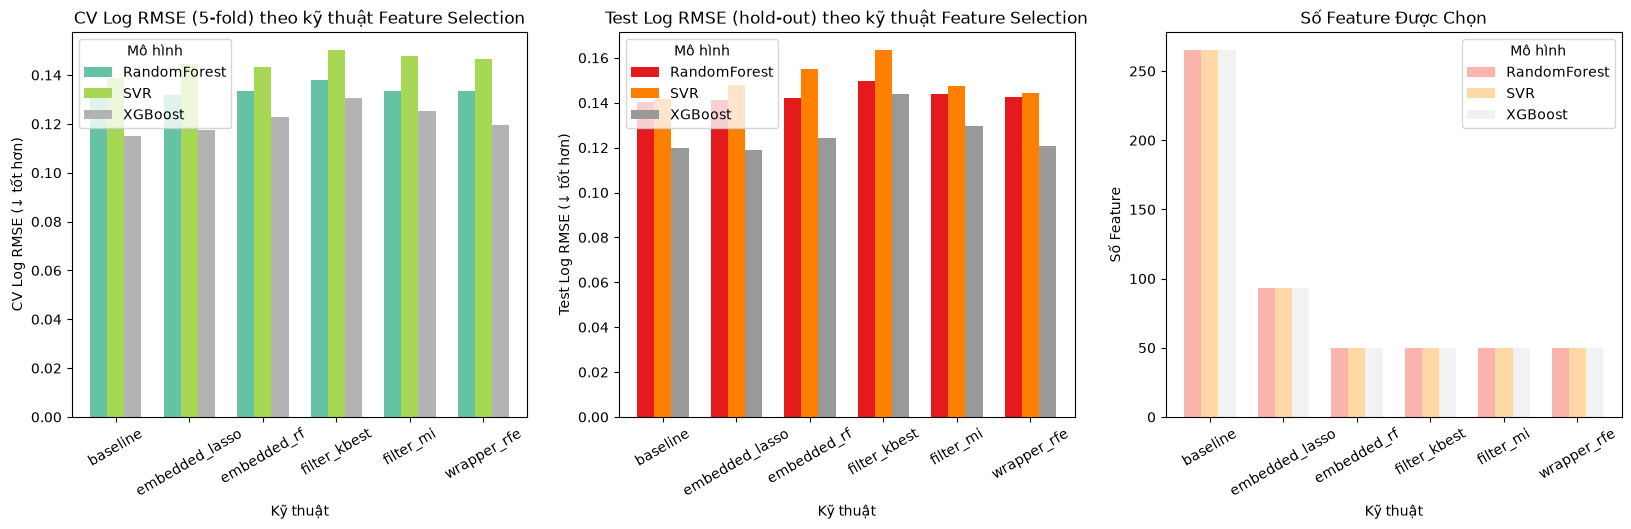

In [6]:
# Biểu đồ 1: CV vs Test Log RMSE theo kỹ thuật & mô hình 
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

pivot_cv_rmse   = results.pivot(index='technique', columns='model', values='cv_log_rmse')
pivot_test_rmse = results.pivot(index='technique', columns='model', values='test_log_rmse')
pivot_feat      = results.pivot(index='technique', columns='model', values='n_features')

pivot_cv_rmse.plot(kind='bar', ax=axes[0], colormap='Set2', width=0.7)
axes[0].set_title('CV Log RMSE (5-fold) theo kỹ thuật Feature Selection', fontsize=12)
axes[0].set_xlabel('Kỹ thuật')
axes[0].set_ylabel('CV Log RMSE (↓ tốt hơn)')
axes[0].legend(title='Mô hình')
axes[0].tick_params(axis='x', rotation=30)

pivot_test_rmse.plot(kind='bar', ax=axes[1], colormap='Set1', width=0.7)
axes[1].set_title('Test Log RMSE (hold-out) theo kỹ thuật Feature Selection', fontsize=12)
axes[1].set_xlabel('Kỹ thuật')
axes[1].set_ylabel('Test Log RMSE (↓ tốt hơn)')
axes[1].legend(title='Mô hình')
axes[1].tick_params(axis='x', rotation=30)

pivot_feat.plot(kind='bar', ax=axes[2], colormap='Pastel1', width=0.7)
axes[2].set_title('Số Feature Được Chọn', fontsize=12)
axes[2].set_xlabel('Kỹ thuật')
axes[2].set_ylabel('Số Feature')
axes[2].legend(title='Mô hình')
axes[2].tick_params(axis='x', rotation=30)



Text(846.7492700441918, 0.5, 'Kỹ thuật Feature Selection')

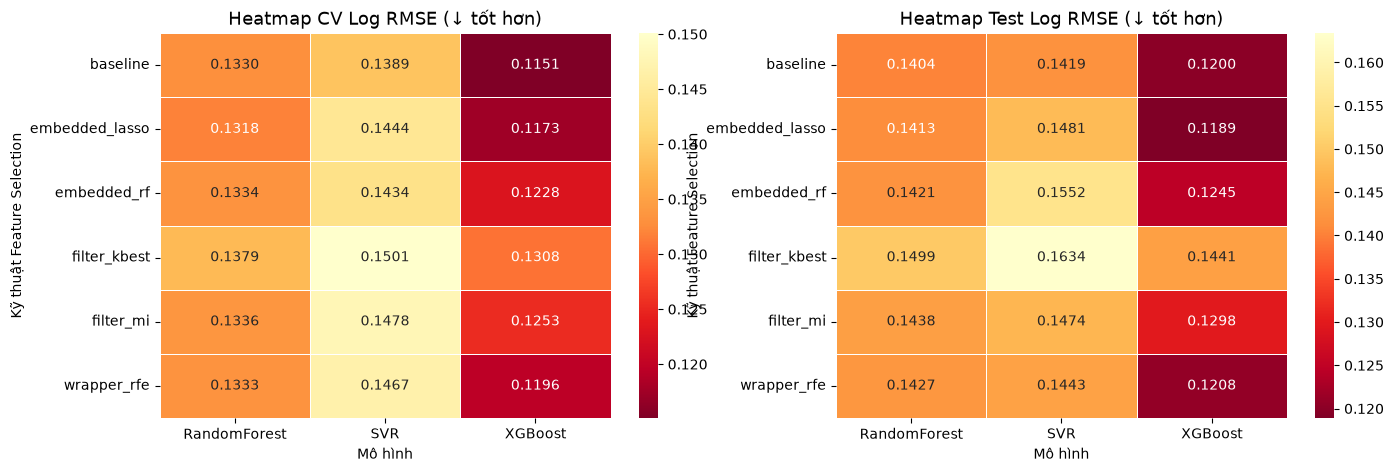

In [7]:
# Biểu đồ 2: Heatmap CV RMSE & Test RMSE 
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(
    pivot_cv_rmse.round(4),
    annot=True, fmt='.4f', cmap='YlOrRd_r',
    linewidths=0.5, ax=axes[0],
)
axes[0].set_title('Heatmap CV Log RMSE (↓ tốt hơn)', fontsize=13)
axes[0].set_xlabel('Mô hình')
axes[0].set_ylabel('Kỹ thuật Feature Selection')

sns.heatmap(
    pivot_test_rmse.round(4),
    annot=True, fmt='.4f', cmap='YlOrRd_r',
    linewidths=0.5, ax=axes[1],
)
axes[1].set_title('Heatmap Test Log RMSE (↓ tốt hơn)', fontsize=13)
axes[1].set_xlabel('Mô hình')
axes[1].set_ylabel('Kỹ thuật Feature Selection')

